# Лабораторна робота №1 "Linear Regression"
**Мета.** Навчитись реалізовувати лінійну регресію та градієнтний спуск.

## Хід роботи

### Завантаження даних
Імпортуємо необхідні бібліотеки:

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Завантажуємо train та test дані з CSV-файлів за допомогою `numpy` (перша колонка — індекс, тому її пропускаємо), де _x_ – ознака, _y_ – цільове значення:

In [2]:
def load_csv(path):
    data = np.loadtxt(path, delimiter=",", skiprows=1, usecols=(1, 2))
    return data[:, 0], data[:, 1]


x_train, y_train = load_csv("data/lab_1_train.csv")
x_test, y_test = load_csv("data/lab_1_test.csv")

Виведемо форму масивів та перші рядки тренувальних даних:

In [3]:
print("Train:", x_train.shape, y_train.shape)
print("Test: ", x_test.shape, y_test.shape)
print("Перші 5 рядків train (x, y):")
print(np.column_stack((x_train, y_train))[:5])

Train: (60,) (60,)
Test:  (40,) (40,)
Перші 5 рядків train (x, y):
[[0.00000000e+00 2.01490142e+01]
 [1.01010101e-02 1.99787227e+01]
 [2.02020202e-02 2.02347106e+01]
 [3.03030303e-02 2.05175150e+01]
 [4.04040404e-02 2.00105621e+01]]


### Візуалізація train даних
Побудуємо діаграму розсіювання тренувальних даних, щоб побачити залежність $y$ від $x$:

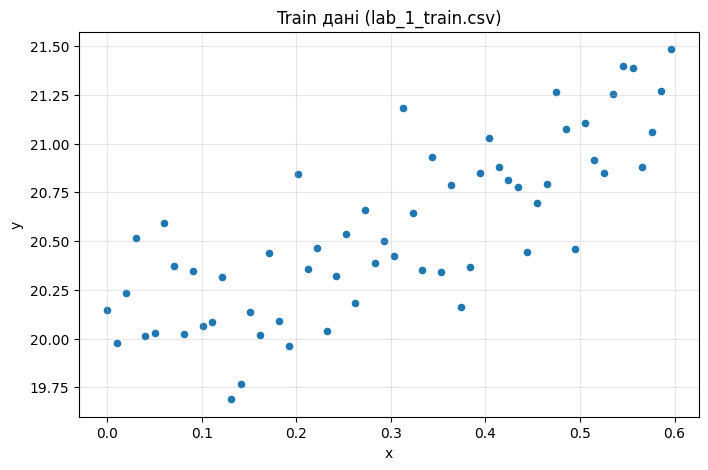

In [4]:
plt.figure(figsize=(8, 5))
plt.scatter(x_train, y_train, s=20, color="tab:blue")
plt.title("Train дані (lab_1_train.csv)")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(alpha=0.3)
plt.show()

### Лінійна регресія
Модель:
$$h_\theta(x) = \theta_0 + \theta_1 x,$$
де $h_\theta(x)$ – передбачене моделлю значення цільової змінної для ознаки $x$; <br>
$\theta_0$ – вільний член (точка перетину прямої з віссю $y$); <br>
$\theta_1$ – нахил прямої (на скільки в середньому змінюється $y$, коли $x$ зростає на 1).

Функція втрат – середньоквадратична помилка (MSE):
$$J(\theta_0, \theta_1) = \frac{1}{m}\sum_{i=1}^{m} \left(h_\theta(x^{(i)}) - y^{(i)}\right)^2 = \frac{1}{m}\sum_{i=1}^{m} \left(\theta_0 + \theta_1 x^{(i)} - y^{(i)}\right)^2,$$
де $J(\theta_0, \theta_1)$ (скорочено $J(\theta)$) – значення втрат при параметрах $\theta = (\theta_0, \theta_1)$; <br>
$m$ – кількість прикладів у тренувальній вибірці; <br>
$x^{(i)}$, $y^{(i)}$ – ознака та справжнє цільове значення $i$-го прикладу; <br>
$h_\theta(x^{(i)}) - y^{(i)}$ – помилка передбачення на $i$-му прикладі.

Часткові похідні функції втрат за параметрами (градієнт):
$$\frac{\partial}{\partial \theta_0} J(\theta) = \frac{2}{m}\sum_{i=1}^{m}\left(h_\theta(x^{(i)})-y^{(i)}\right), \qquad \frac{\partial}{\partial \theta_1} J(\theta) = \frac{2}{m}\sum_{i=1}^{m}\left(h_\theta(x^{(i)})-y^{(i)}\right)x^{(i)},$$
де кожна похідна показує, як змінюються втрати при невеликій зміні відповідного параметра: знак – у який бік, модуль – наскільки сильно.

Навчаємо модель класичним градієнтним спуском: за одну епоху виконується рівно одне оновлення параметрів, обчислене на всій тренувальній вибірці:
$$\theta_j^{(t+1)} = \theta_j^{(t)} - \alpha \frac{\partial}{\partial \theta_j} J(\theta^{(t)}),$$
де $\theta_j^{(t)}$, $\theta_j^{(t+1)}$ – значення параметра до та після оновлення на епосі $t$; <br>
$j \in \{0, 1\}$ – номер параметра (обидва оновлюються одночасно, за значеннями $\theta^{(t)}$); <br>
$\alpha$ – крок навчання (learning rate), що визначає розмір кроку проти напрямку градієнта.

Вважаємо, що спуск зійшовся, коли зміна втрат за епоху стає меншою за `eps`.

In [5]:
def mse(y_pred, y_true):
    return np.mean((y_pred - y_true) ** 2)


class LinearRegression:
    def __init__(self, alpha=0.5, max_epochs=100_000, eps=1e-6):
        self.alpha = alpha
        self.max_epochs = max_epochs
        self.eps = eps
        self.theta0 = 0.0
        self.theta1 = 0.0
        self.history = []  # (epoch, theta0, theta1, loss) після кожної епохи

    def predict(self, x):
        return self.theta0 + self.theta1 * x

    def fit(self, x, y, verbose=True):
        prev_loss = mse(self.predict(x), y)
        for epoch in range(1, self.max_epochs + 1):
            error = self.predict(x) - y
            grad_theta0 = 2 * np.mean(error)
            grad_theta1 = 2 * np.mean(error * x)
            self.theta0 -= self.alpha * grad_theta0
            self.theta1 -= self.alpha * grad_theta1

            loss = mse(self.predict(x), y)
            self.history.append((epoch, self.theta0, self.theta1, loss))
            if verbose:
                print(f"Епоха {epoch:4d}: θ0 = {self.theta0:.6f}, θ1 = {self.theta1:.6f}, MSE = {loss:.6f}")
            if abs(prev_loss - loss) < self.eps:
                break
            prev_loss = loss
        return self

Навчаємо модель **лише на train даних** з кроком навчання $\alpha = 0.5$. Test дані до навчання не залучаються, вони потрібні тільки для оцінки вже навченої моделі. Після кожної епохи виводимо поточні значення параметрів $\theta_0$, $\theta_1$ та функції втрат (MSE):

In [6]:
model = LinearRegression(alpha=0.5).fit(x_train, y_train)

epochs, theta0, theta1, train_loss = model.history[-1]
print(f"Зійшлося за {epochs} епох: θ0 = {theta0:.4f}, θ1 = {theta1:.4f}, train MSE = {train_loss:.4f}")

Епоха    1: θ0 = 20.549563, θ1 = 6.183907, MSE = 4.009614
Епоха    2: θ0 = 18.706884, θ1 = 5.506146, MSE = 0.494564
Епоха    3: θ0 = 18.908843, θ1 = 5.458386, MSE = 0.443738
Епоха    4: θ0 = 18.923074, θ1 = 5.356149, MSE = 0.423012
Епоха    5: θ0 = 18.953539, θ1 = 5.261878, MSE = 0.403659
Епоха    6: θ0 = 18.981630, θ1 = 5.169783, MSE = 0.385378
Епоха    7: θ0 = 19.009072, θ1 = 5.080314, MSE = 0.368108
Епоха    8: θ0 = 19.035732, θ1 = 4.993350, MSE = 0.351793
Епоха    9: θ0 = 19.061646, θ1 = 4.908824, MSE = 0.336380
Епоха   10: θ0 = 19.086833, θ1 = 4.826668, MSE = 0.321819
Епоха   11: θ0 = 19.111314, θ1 = 4.746816, MSE = 0.308063
Епоха   12: θ0 = 19.135108, θ1 = 4.669203, MSE = 0.295068
Епоха   13: θ0 = 19.158235, θ1 = 4.593766, MSE = 0.282791
Епоха   14: θ0 = 19.180714, θ1 = 4.520444, MSE = 0.271193
Епоха   15: θ0 = 19.202562, θ1 = 4.449178, MSE = 0.260237
Епоха   16: θ0 = 19.223798, θ1 = 4.379910, MSE = 0.249886
Епоха   17: θ0 = 19.244438, θ1 = 4.312585, MSE = 0.240108
Епоха   18: θ0

Отже, маємо рівняння: $h_\theta(x) = 19.9528 + 2.0021x$

### Оцінка на test даних
Після того, як градієнтний спуск зійшовся, обчислюємо функцію втрат $J(\theta)$ (MSE) навченої моделі на test даних (параметри $\theta_0$, $\theta_1$ більше не змінюються):

In [7]:
test_loss = mse(model.predict(x_test), y_test)
print(f"Train MSE = {train_loss:.4f}")
print(f"Test MSE  = {test_loss:.4f}")

Train MSE = 0.0731
Test MSE  = 0.0747


### Фінальна візуалізація
Зобразимо на одному графіку train дані (сині кола), test дані (зелені кола) та отриману пряму регресії:

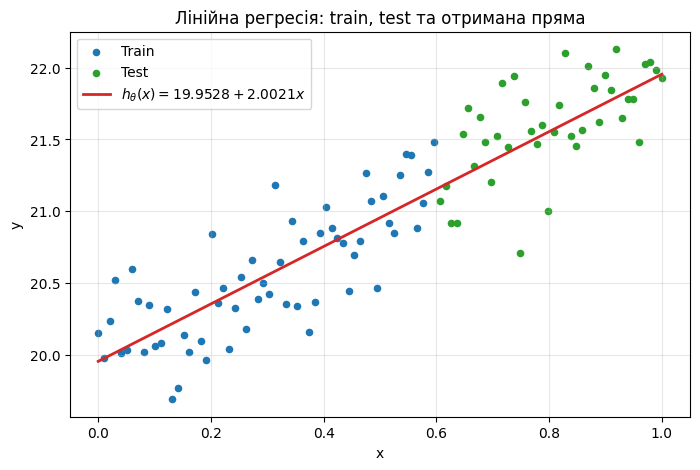

In [8]:
x_line = np.linspace(min(x_train.min(), x_test.min()), max(x_train.max(), x_test.max()), 100)

plt.figure(figsize=(8, 5))
plt.scatter(x_train, y_train, s=20, color="tab:blue", label="Train")
plt.scatter(x_test, y_test, s=20, color="tab:green", label="Test")
plt.plot(x_line, model.predict(x_line), color="tab:red", linewidth=2,
         label=rf"$h_\theta(x) = {model.theta0:.4f} + {model.theta1:.4f}x$")
plt.title("Лінійна регресія: train, test та отримана пряма")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## Висновок
У ході лабораторної роботи було реалізовано одновимірну лінійну регресію $h_\theta(x) = \theta_0 + \theta_1 x$. Параметри моделі навчались класичним (batch) градієнтним спуском: на кожній епосі обчислювався градієнт функції втрат MSE на всій тренувальній вибірці та виконувалось одне оновлення параметрів.

Візуалізація train даних показала чітку лінійну залежність $y$ від $x$ з невеликим шумом, тому лінійна модель є доречною для цих даних. При кроці навчання $\alpha = 0.5$ та критерії зупинки $\varepsilon = 10^{-6}$ (зміна втрат за епоху) градієнтний спуск зійшовся за 179 епох до рівняння $h_\theta(x) = 19.9528 + 2.0021x$.

Модель навчалась лише на train даних, а test дані використовувались тільки для оцінки вже навченої моделі. Значення MSE на train (0.0731) та test (0.0747) даних майже однакові. Це також підтверджує фінальний графік: отримана пряма проходить через обидві хмари точок.